# BD-PaveSurface Reproducibility Workflow

This notebook reproduces the finalized dataset-preparation and baseline-validation workflow used for BD-PaveSurface.

## Workflow

1. Read the **9,000 cleaned original images**.
2. Extract ImageNet-pretrained ResNet50 penultimate embeddings for scene-similarity grouping.
3. Use cosine similarity with threshold **0.95** for conservative within-class scene grouping.
4. Assign complete scene groups to train/validation/test at approximately **70:15:15**.
5. Verify that no scene group crosses train/validation/test.
6. Perform an exact-file SHA-256 cross-split duplicate audit.
7. Convert every original image to RGB and resize it to **224 × 224**.
8. Generate exactly **1,000 augmented images per class from training originals only**.
9. Keep validation and test free of augmentation.
10. Train ResNet50, DenseNet121, MobileNetV2, and EfficientNetB0 using the documented baseline procedure.
11. Select the best checkpoint using minimum validation loss.
12. Evaluate the selected checkpoint on the untouched test set.
13. Save overall metrics, per-class metrics, training histories, and confusion matrices.

> Run the cells in order. The displayed outputs come from the completed Windows run and therefore show the original local F: drive paths. Update `RAW_ROOT` and `PROJECT_ROOT` before rerunning on another computer.



## 0. Optional package installation

Uncomment and run only when a package is missing.


In [13]:

# %pip install torch torchvision scikit-learn pandas numpy pillow matplotlib tqdm


## 1. Imports and configuration

In [14]:

import os
import gc
import json
import math
import random
import shutil
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.datasets import ImageFolder
import torchvision.transforms as T
from torch.optim.lr_scheduler import ReduceLROnPlateau

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = False

# -----------------------------
# USER PATHS
# -----------------------------
RAW_ROOT = Path(r"F:\Road Dataset\Raw Data")
PROJECT_ROOT = Path(r"F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095")
PROCESSED_ROOT = PROJECT_ROOT / "processed_scene_split_12000_strict095"
RESULTS_ROOT = PROJECT_ROOT / "results_strict095"
CACHE_ROOT = PROJECT_ROOT / "cache_strict095"

# Raw folders expected inside RAW_ROOT
CLASSES = ["Crack", "Good", "Pothole"]

# -----------------------------
# DATASET SETTINGS
# -----------------------------
IMG_SIZE = 224
SEED = 17
SPLIT_RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}

# Conservative similarity threshold.
# Increase it if unrelated scenes are grouped together.
# Decrease it slightly if obvious repeated views remain separated.
SIMILARITY_THRESHOLD = 0.95

# Offline augmentations added only to training:
AUGMENTED_PER_CLASS = 1000

# Number of random restarts used to find a balanced scene-level split.
SPLIT_RESTARTS = 1000

# -----------------------------
# COMPUTE SETTINGS
# -----------------------------
EMBED_BATCH_SIZE = 32
TRAIN_BATCH_SIZE = 16
EPOCHS = 30
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 10
NUM_WORKERS = 0

# Set True only when you intentionally want to rebuild all processed images.
REBUILD_PROCESSED_DATASET = True

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"
}

PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
CACHE_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Raw dataset:", RAW_ROOT)
print("Project output:", PROJECT_ROOT)


Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
Raw dataset: F:\Road Dataset\Raw Data
Project output: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095


## 2. Reproducibility

A fixed rerun seed (`17`) is used for scene assignment, augmentation sampling,
DataLoader shuffling, and baseline training. The original methodology and
hyperparameters are otherwise retained.


In [15]:

def set_global_seed(seed: int = 42) -> None:
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Deterministic settings. This is slower but more reproducible.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


set_global_seed(SEED)
print("Global seed:", SEED)


Global seed: 17


## 3. Validate and index the original dataset

In [16]:

def list_images(folder: Path):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    )


def validate_image(path: Path):
    try:
        with Image.open(path) as im:
            im.verify()
        return True, ""
    except Exception as exc:
        return False, str(exc)


if not RAW_ROOT.exists():
    raise FileNotFoundError(
        f"RAW_ROOT does not exist: {RAW_ROOT}\n"
        "Check the drive letter and folder path."
    )

records = []
bad_images = []

for class_name in CLASSES:
    class_dir = RAW_ROOT / class_name
    if not class_dir.exists():
        raise FileNotFoundError(
            f"Missing class folder: {class_dir}\n"
            f"Expected folders: {CLASSES}"
        )

    paths = list_images(class_dir)
    print(f"{class_name}: found {len(paths)} image files")

    for path in tqdm(paths, desc=f"Checking {class_name}"):
        ok, error = validate_image(path)
        if ok:
            records.append({
                "filepath": str(path),
                "filename": path.name,
                "class": class_name,
            })
        else:
            bad_images.append({
                "filepath": str(path),
                "class": class_name,
                "error": error,
            })

raw_df = pd.DataFrame(records)
bad_df = pd.DataFrame(bad_images)

print("\nValid image counts:")
display(raw_df.groupby("class").size().rename("count").to_frame())

if not bad_df.empty:
    bad_path = RESULTS_ROOT / "unreadable_images.csv"
    bad_df.to_csv(bad_path, index=False)
    print(f"Unreadable images found: {len(bad_df)}")
    print("Saved:", bad_path)
    raise RuntimeError(
        "Remove or replace unreadable images, then rerun this cell."
    )

expected_counts = {class_name: 3000 for class_name in CLASSES}
actual_counts = raw_df.groupby("class").size().to_dict()

for class_name, expected in expected_counts.items():
    actual = actual_counts.get(class_name, 0)
    if actual != expected:
        print(
            f"WARNING: {class_name} has {actual} valid images; "
            f"the manuscript currently expects {expected}."
        )

raw_index_path = CACHE_ROOT / "raw_image_index.csv"
raw_df.to_csv(raw_index_path, index=False)
print("Saved raw index:", raw_index_path)


Crack: found 3000 image files


Checking Crack:   0%|          | 0/3000 [00:00<?, ?it/s]

Good: found 3000 image files


Checking Good:   0%|          | 0/3000 [00:00<?, ?it/s]

Pothole: found 3000 image files


Checking Pothole:   0%|          | 0/3000 [00:00<?, ?it/s]


Valid image counts:


,count
class,
Crack,3000
Good,3000
Pothole,3000


Saved raw index: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\cache_strict095\raw_image_index.csv



## 4. Extract similarity embeddings

The final classification layer of ImageNet-pretrained ResNet50 is replaced by an identity layer.  
The resulting normalized feature vectors are used only for conservative visual-similarity grouping.

The embedding cache is reused automatically when it matches the current file index.


In [17]:

class EmbeddingDataset(Dataset):
    def __init__(self, dataframe: pd.DataFrame, transform):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        path = Path(self.dataframe.loc[index, "filepath"])
        with Image.open(path) as im:
            image = im.convert("RGB")
        return self.transform(image), index


def extract_embeddings(dataframe: pd.DataFrame):
    cache_path = CACHE_ROOT / "resnet50_embeddings.npz"
    signature = dataframe["filepath"].astype(str).tolist()

    if cache_path.exists():
        cached = np.load(cache_path, allow_pickle=True)
        cached_paths = cached["paths"].tolist()
        if cached_paths == signature:
            print("Loading cached embeddings:", cache_path)
            return cached["embeddings"].astype(np.float32)

    weights = models.ResNet50_Weights.DEFAULT
    transform = weights.transforms()

    backbone = models.resnet50(weights=weights)
    backbone.fc = nn.Identity()
    backbone = backbone.to(device)
    backbone.eval()

    dataset = EmbeddingDataset(dataframe, transform)
    loader = DataLoader(
        dataset,
        batch_size=EMBED_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=NUM_WORKERS > 0,
    )

    embeddings = np.zeros((len(dataset), 2048), dtype=np.float32)

    with torch.inference_mode():
        for images, indices in tqdm(loader, desc="Extracting embeddings"):
            images = images.to(device, non_blocking=True)
            features = backbone(images)
            features = torch.nn.functional.normalize(features, p=2, dim=1)
            embeddings[indices.numpy()] = features.cpu().numpy().astype(np.float32)

    np.savez_compressed(
        cache_path,
        embeddings=embeddings,
        paths=np.array(signature, dtype=object),
    )
    print("Saved embedding cache:", cache_path)

    del backbone, loader, dataset
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return embeddings


embeddings = extract_embeddings(raw_df)
print("Embedding matrix:", embeddings.shape)


Extracting embeddings:   0%|          | 0/282 [00:00<?, ?it/s]

Saved embedding cache: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\cache_strict095\resnet50_embeddings.npz
Embedding matrix: (9000, 2048)



## 5. Create conservative similarity-based scene groups

Grouping is performed **within each class**, so a Crack image cannot be grouped with Good or Pothole.

Complete-linkage clustering is used to reduce chain-merging: every member of a group must remain conservatively close to the group under the selected cosine-distance threshold.

After grouping, inspect the largest groups. If unrelated locations are merged, increase `SIMILARITY_THRESHOLD`, then rerun this cell and the following cells.


In [18]:

def make_agglomerative_clusterer(distance_threshold: float):
    common = dict(
        n_clusters=None,
        linkage="complete",
        distance_threshold=distance_threshold,
        compute_full_tree=True,
    )

    # Compatibility with both newer and older scikit-learn releases.
    try:
        return AgglomerativeClustering(metric="cosine", **common)
    except TypeError:
        return AgglomerativeClustering(affinity="cosine", **common)


def create_scene_groups(
    dataframe: pd.DataFrame,
    feature_matrix: np.ndarray,
    similarity_threshold: float,
):
    distance_threshold = 1.0 - similarity_threshold
    parts = []

    for class_name in CLASSES:
        class_indices = dataframe.index[dataframe["class"] == class_name].to_numpy()
        class_features = feature_matrix[class_indices]

        print(
            f"Grouping {class_name}: {len(class_indices)} images | "
            f"similarity threshold = {similarity_threshold:.4f}"
        )

        clusterer = make_agglomerative_clusterer(distance_threshold)
        local_labels = clusterer.fit_predict(class_features)

        class_part = dataframe.loc[class_indices].copy()
        class_part["local_scene_label"] = local_labels
        class_part["scene_id"] = [
            f"{class_name.upper()}_SCENE_{label:05d}"
            for label in local_labels
        ]
        parts.append(class_part)

    scene_df = pd.concat(parts, ignore_index=True)
    scene_df = scene_df.drop(columns=["local_scene_label"])

    # Stable order for reproducibility and review.
    scene_df = scene_df.sort_values(
        ["class", "scene_id", "filename"]
    ).reset_index(drop=True)

    return scene_df


scene_df = create_scene_groups(
    raw_df,
    embeddings,
    SIMILARITY_THRESHOLD,
)

scene_sizes = (
    scene_df.groupby(["class", "scene_id"])
    .size()
    .rename("images")
    .reset_index()
    .sort_values(["class", "images"], ascending=[True, False])
)

print("\nScene summary:")
display(
    scene_sizes.groupby("class")["images"]
    .agg(number_of_scenes="count", largest_scene="max", median_scene="median")
)

print("\nLargest scene groups:")
display(scene_sizes.head(20))

scene_groups_path = CACHE_ROOT / "scene_groups_before_split.csv"
scene_df.to_csv(scene_groups_path, index=False)
print("Saved:", scene_groups_path)


Grouping Crack: 3000 images | similarity threshold = 0.9500
Grouping Good: 3000 images | similarity threshold = 0.9500
Grouping Pothole: 3000 images | similarity threshold = 0.9500

Scene summary:


,number_of_scenes,largest_scene,median_scene
class,,,
Crack,1826,10,1.0
Good,1441,58,1.0
Pothole,2431,10,1.0



Largest scene groups:


,class,scene_id,images
130,Crack,CRACK_SCENE_00130,10
206,Crack,CRACK_SCENE_00206,8
340,Crack,CRACK_SCENE_00340,8
103,Crack,CRACK_SCENE_00103,7
153,Crack,CRACK_SCENE_00153,7
269,Crack,CRACK_SCENE_00269,7
308,Crack,CRACK_SCENE_00308,7
8,Crack,CRACK_SCENE_00008,6
16,Crack,CRACK_SCENE_00016,6
40,Crack,CRACK_SCENE_00040,6


Saved: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\cache_strict095\scene_groups_before_split.csv



### Optional visual inspection of a scene group

Change `SCENE_TO_VIEW` to one of the IDs shown above.


In [19]:

def show_scene(scene_id: str, max_images: int = 12):
    subset = scene_df[scene_df["scene_id"] == scene_id].head(max_images)

    if subset.empty:
        print("Scene ID not found:", scene_id)
        return

    n = len(subset)
    cols = min(4, n)
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.atleast_1d(axes).ravel()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, subset.iterrows()):
        with Image.open(row["filepath"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(row["filename"], fontsize=8)
        ax.axis("off")

    fig.suptitle(scene_id)
    plt.tight_layout()
    plt.show()


# Example:
# SCENE_TO_VIEW = scene_sizes.iloc[0]["scene_id"]
# show_scene(SCENE_TO_VIEW)



## 6. Balanced 70:15:15 assignment at scene level

The split optimizer works independently for each class.

Priority:

1. A scene is never divided.
2. Each class remains as close as possible to 70:15:15.
3. The selected assignment is the best of multiple seeded restarts.


In [20]:

SPLIT_NAMES = ["train", "val", "test"]


def split_error(counts: dict, targets: dict) -> float:
    normalized_squared_error = 0.0
    maximum_relative_deviation = 0.0

    for split_name in SPLIT_NAMES:
        target = max(float(targets[split_name]), 1.0)
        deviation = abs(float(counts[split_name]) - target) / target
        normalized_squared_error += deviation ** 2
        maximum_relative_deviation = max(maximum_relative_deviation, deviation)

    # The max-deviation term discourages one split from becoming much worse.
    return normalized_squared_error + 0.25 * maximum_relative_deviation


def assign_scene_groups_for_one_class(
    class_scene_sizes: pd.DataFrame,
    ratios: dict,
    seed: int,
    restarts: int,
):
    groups = list(
        class_scene_sizes[["scene_id", "images"]]
        .itertuples(index=False, name=None)
    )
    total_images = sum(size for _, size in groups)
    targets = {
        split_name: total_images * ratios[split_name]
        for split_name in SPLIT_NAMES
    }

    best_assignment = None
    best_counts = None
    best_score = float("inf")

    for restart in range(restarts):
        rng = random.Random(seed + restart)

        # Large groups first, randomized only among similar sizes.
        ordered = sorted(
            groups,
            key=lambda item: (-item[1], rng.random())
        )

        counts = {split_name: 0 for split_name in SPLIT_NAMES}
        assignment = {}

        for scene_id, scene_size in ordered:
            candidate_scores = {}

            for split_name in SPLIT_NAMES:
                projected = counts.copy()
                projected[split_name] += scene_size

                score = split_error(projected, targets)

                # Soft penalty for exceeding the target too early.
                overfill = max(
                    projected[split_name] - targets[split_name],
                    0.0
                ) / max(targets[split_name], 1.0)
                score += 0.15 * (overfill ** 2)

                candidate_scores[split_name] = score

            minimum = min(candidate_scores.values())
            best_candidates = [
                name for name, value in candidate_scores.items()
                if abs(value - minimum) < 1e-12
            ]
            chosen_split = rng.choice(best_candidates)

            assignment[scene_id] = chosen_split
            counts[chosen_split] += scene_size

        score = split_error(counts, targets)

        if score < best_score:
            best_score = score
            best_assignment = assignment.copy()
            best_counts = counts.copy()

    return best_assignment, best_counts, targets, best_score


scene_size_table = (
    scene_df.groupby(["class", "scene_id"])
    .size()
    .rename("images")
    .reset_index()
)

scene_to_split = {}
optimization_rows = []

for class_offset, class_name in enumerate(CLASSES):
    class_table = scene_size_table[
        scene_size_table["class"] == class_name
    ].copy()

    assignment, counts, targets, score = assign_scene_groups_for_one_class(
        class_table,
        SPLIT_RATIOS,
        seed=SEED + class_offset * 10000,
        restarts=SPLIT_RESTARTS,
    )

    scene_to_split.update(assignment)

    for split_name in SPLIT_NAMES:
        optimization_rows.append({
            "class": class_name,
            "split": split_name,
            "images": counts[split_name],
            "target_images": targets[split_name],
            "difference": counts[split_name] - targets[split_name],
        })

scene_df["split"] = scene_df["scene_id"].map(scene_to_split)

if scene_df["split"].isna().any():
    raise RuntimeError("Some scenes were not assigned to a split.")

split_counts = pd.crosstab(scene_df["split"], scene_df["class"])
split_counts = split_counts.reindex(index=SPLIT_NAMES, columns=CLASSES, fill_value=0)
split_counts["Total"] = split_counts.sum(axis=1)

print("Original-image split counts:")
display(split_counts)

optimization_df = pd.DataFrame(optimization_rows)
print("Deviation from class-wise targets:")
display(optimization_df)

scene_split_path = PROJECT_ROOT / "scene_split.csv"
scene_df[["filepath", "filename", "class", "scene_id", "split"]].to_csv(
    scene_split_path,
    index=False,
)
print("Saved:", scene_split_path)


Original-image split counts:


class,Crack,Good,Pothole,Total
split,,,,
train,2100,2100,2100,6300
val,450,450,450,1350
test,450,450,450,1350


Deviation from class-wise targets:


,class,split,images,target_images,difference
0,Crack,train,2100,2100.0,0.0
1,Crack,val,450,450.0,0.0
2,Crack,test,450,450.0,0.0
3,Good,train,2100,2100.0,0.0
4,Good,val,450,450.0,0.0
5,Good,test,450,450.0,0.0
6,Pothole,train,2100,2100.0,0.0
7,Pothole,val,450,450.0,0.0
8,Pothole,test,450,450.0,0.0


Saved: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\scene_split.csv


## 7. Verify zero scene overlap

In [21]:

scene_split_cardinality = scene_df.groupby("scene_id")["split"].nunique()
overlapping_scenes = scene_split_cardinality[scene_split_cardinality > 1]

if len(overlapping_scenes) != 0:
    raise AssertionError(
        f"Scene leakage detected: {len(overlapping_scenes)} scene groups "
        "occur in more than one split."
    )

summary_rows = []

for split_name in SPLIT_NAMES:
    subset = scene_df[scene_df["split"] == split_name]
    row = {
        "split": split_name,
        "original_images": len(subset),
        "scene_groups": subset["scene_id"].nunique(),
        "augmented_images": 0,
    }
    for class_name in CLASSES:
        row[class_name] = int((subset["class"] == class_name).sum())
    summary_rows.append(row)

split_summary_df = pd.DataFrame(summary_rows)
split_summary_df["scene_overlap_across_splits"] = 0
split_summary_df["similarity_threshold"] = SIMILARITY_THRESHOLD
split_summary_df["random_seed"] = SEED

split_summary_path = PROJECT_ROOT / "split_summary.csv"
split_summary_df.to_csv(split_summary_path, index=False)

print("PASS: scene overlap across train/val/test = 0")
display(split_summary_df)
print("Saved:", split_summary_path)


PASS: scene overlap across train/val/test = 0


,split,original_images,scene_groups,augmented_images,Crack,Good,Pothole,scene_overlap_across_splits,similarity_threshold,random_seed
0,train,6300,4715,0,2100,2100,2100,0,0.95,17
1,val,1350,491,0,450,450,450,0,0.95,17
2,test,1350,492,0,450,450,450,0,0.95,17


Saved: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\split_summary.csv



## 7A. Strict exact cross-split duplicate audit

In addition to scene-level grouping, this audit computes SHA256 for all
9,000 original images and verifies that an identical file does not occur
across train, validation, and test.


In [22]:

import hashlib


def compute_sha256(
    file_path: Path,
    chunk_size: int = 1024 * 1024,
):
    digest = hashlib.sha256()

    with open(
        file_path,
        "rb",
    ) as handle:
        while True:
            chunk = handle.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


hash_audit_path = (
    RESULTS_ROOT
    / "strict095_sha256_cross_split_audit.csv"
)

hash_rows = []

for _, row in tqdm(
    scene_df.iterrows(),
    total=len(scene_df),
    desc="SHA256 audit",
):
    hash_rows.append({
        "filepath": row["filepath"],
        "filename": row["filename"],
        "class": row["class"],
        "scene_id": row["scene_id"],
        "split": row["split"],
        "sha256": compute_sha256(
            Path(row["filepath"])
        ),
    })

hash_df = pd.DataFrame(
    hash_rows
)

hash_df.to_csv(
    hash_audit_path,
    index=False,
)

hash_split_cardinality = (
    hash_df.groupby(
        "sha256"
    )["split"]
    .nunique()
)

cross_split_hashes = (
    hash_split_cardinality[
        hash_split_cardinality > 1
    ]
)

exact_cross_split_duplicates = int(
    len(
        cross_split_hashes
    )
)

print(
    "Exact SHA256 hashes occurring in multiple splits:",
    exact_cross_split_duplicates,
)

if exact_cross_split_duplicates != 0:
    duplicate_rows = (
        hash_df[
            hash_df[
                "sha256"
            ].isin(
                cross_split_hashes.index
            )
        ]
        .sort_values(
            [
                "sha256",
                "split",
            ]
        )
    )

    display(
        duplicate_rows.head(
            50
        )
    )

    raise AssertionError(
        "Exact image duplicates were detected across splits."
    )

print(
    "PASS: no exact SHA256 duplicate occurs across train/validation/test."
)

print(
    "Saved:",
    hash_audit_path,
)


SHA256 audit:   0%|          | 0/9000 [00:00<?, ?it/s]

Exact SHA256 hashes occurring in multiple splits: 0
PASS: no exact SHA256 duplicate occurs across train/validation/test.
Saved: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\results_strict095\strict095_sha256_cross_split_audit.csv



## 8. Build the corrected 12,000-file processed dataset

- All 9,000 originals are resized to `224 × 224`.
- Exactly 1,000 augmented images per class are generated.
- Augmented images are generated only from originals assigned to `train`.
- Validation and test contain only resized original images.


In [23]:

def safe_reset_directory(path: Path):
    if path.exists():
        shutil.rmtree(path)
    path.mkdir(parents=True, exist_ok=True)


def save_rgb_224(source_path: Path, destination_path: Path):
    with Image.open(source_path) as im:
        image = im.convert("RGB")
        image = image.resize(
            (IMG_SIZE, IMG_SIZE),
            resample=Image.Resampling.LANCZOS,
        )
        image.save(
            destination_path,
            format="JPEG",
            quality=95,
            subsampling=0,
        )


offline_train_augmentation = T.Compose([
    T.RandomResizedCrop(
        IMG_SIZE,
        scale=(0.75, 1.00),
        ratio=(0.90, 1.10),
    ),
    T.RandomHorizontalFlip(p=0.50),
    T.RandomApply(
        [T.RandomRotation(degrees=12)],
        p=0.70,
    ),
    T.RandomPerspective(
        distortion_scale=0.15,
        p=0.25,
    ),
    T.ColorJitter(
        brightness=0.20,
        contrast=0.20,
        saturation=0.10,
        hue=0.02,
    ),
    T.RandomApply(
        [T.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))],
        p=0.20,
    ),
    T.ToTensor(),
    T.RandomErasing(
        p=0.25,
        scale=(0.01, 0.05),
        ratio=(0.3, 3.3),
        value="random",
    ),
    T.ToPILImage(),
])


if REBUILD_PROCESSED_DATASET:
    safe_reset_directory(PROCESSED_ROOT)

    for split_name in SPLIT_NAMES:
        for class_name in CLASSES:
            (PROCESSED_ROOT / split_name / class_name).mkdir(
                parents=True,
                exist_ok=True,
            )

    manifest_rows = []

    # Save every original image into its assigned scene-level split.
    for row_number, row in tqdm(
        scene_df.reset_index(drop=True).iterrows(),
        total=len(scene_df),
        desc="Saving resized originals",
    ):
        source_path = Path(row["filepath"])
        split_name = row["split"]
        class_name = row["class"]

        output_name = (
            f"orig__{row_number:05d}__{source_path.stem}.jpg"
        )
        output_path = PROCESSED_ROOT / split_name / class_name / output_name

        save_rgb_224(source_path, output_path)

        manifest_rows.append({
            "processed_filepath": str(output_path),
            "processed_filename": output_name,
            "class": class_name,
            "split": split_name,
            "is_augmented": False,
            "parent_original": str(source_path),
            "scene_id": row["scene_id"],
        })

    # Generate training-only augmentations.
    augmentation_rng = random.Random(SEED)

    for class_name in CLASSES:
        class_train = scene_df[
            (scene_df["class"] == class_name)
            & (scene_df["split"] == "train")
        ].reset_index(drop=True)

        if class_train.empty:
            raise RuntimeError(f"No training images found for {class_name}")

        source_indices = list(range(len(class_train)))
        repeated_indices = []

        while len(repeated_indices) < AUGMENTED_PER_CLASS:
            shuffled = source_indices.copy()
            augmentation_rng.shuffle(shuffled)
            repeated_indices.extend(shuffled)

        repeated_indices = repeated_indices[:AUGMENTED_PER_CLASS]

        for aug_number, source_index in enumerate(
            tqdm(
                repeated_indices,
                desc=f"Augmenting {class_name}",
            ),
            start=1,
        ):
            source_row = class_train.iloc[source_index]
            source_path = Path(source_row["filepath"])

            # Deterministic per-image augmentation stream.
            per_image_seed = SEED + aug_number + (CLASSES.index(class_name) * 100000)
            random.seed(per_image_seed)
            np.random.seed(per_image_seed)
            torch.manual_seed(per_image_seed)

            with Image.open(source_path) as im:
                image = im.convert("RGB")
                augmented = offline_train_augmentation(image)

            output_name = (
                f"aug__{aug_number:04d}__parent_{source_path.stem}.jpg"
            )
            output_path = PROCESSED_ROOT / "train" / class_name / output_name
            augmented.save(
                output_path,
                format="JPEG",
                quality=95,
                subsampling=0,
            )

            manifest_rows.append({
                "processed_filepath": str(output_path),
                "processed_filename": output_name,
                "class": class_name,
                "split": "train",
                "is_augmented": True,
                "parent_original": str(source_path),
                "scene_id": source_row["scene_id"],
            })

    manifest_df = pd.DataFrame(manifest_rows)
    manifest_path = PROJECT_ROOT / "dataset_manifest.csv"
    manifest_df.to_csv(manifest_path, index=False)

    print("Processed dataset created:", PROCESSED_ROOT)
    print("Saved manifest:", manifest_path)

else:
    manifest_path = PROJECT_ROOT / "dataset_manifest.csv"
    if not manifest_path.exists():
        raise FileNotFoundError(
            "REBUILD_PROCESSED_DATASET is False, but dataset_manifest.csv "
            "does not exist."
        )
    manifest_df = pd.read_csv(manifest_path)
    print("Using existing processed dataset:", PROCESSED_ROOT)


Saving resized originals:   0%|          | 0/9000 [00:00<?, ?it/s]

Augmenting Crack:   0%|          | 0/1000 [00:00<?, ?it/s]

Augmenting Good:   0%|          | 0/1000 [00:00<?, ?it/s]

Augmenting Pothole:   0%|          | 0/1000 [00:00<?, ?it/s]

Processed dataset created: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\processed_scene_split_12000_strict095
Saved manifest: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\dataset_manifest.csv


## 9. Final dataset integrity checks

In [24]:

# 1. Augmentation must exist only in train.
invalid_augmented = manifest_df[
    manifest_df["is_augmented"]
    & (manifest_df["split"] != "train")
]

if not invalid_augmented.empty:
    raise AssertionError(
        "Augmented images were found outside the training split."
    )

# 2. Validation and test augmented counts must be zero.
augmented_counts = (
    manifest_df.groupby(["split", "class"])["is_augmented"]
    .sum()
    .unstack(fill_value=0)
    .reindex(index=SPLIT_NAMES, columns=CLASSES, fill_value=0)
)

# 3. Check file existence.
missing_files = [
    path for path in manifest_df["processed_filepath"]
    if not Path(path).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"{len(missing_files)} processed files are missing."
    )

# 4. Count all files.
final_counts = pd.crosstab(
    [manifest_df["split"], manifest_df["is_augmented"]],
    manifest_df["class"],
).reindex(columns=CLASSES, fill_value=0)
final_counts["Total"] = final_counts.sum(axis=1)

print("Final processed dataset counts:")
display(final_counts)

print("Augmented counts by split:")
display(augmented_counts)

for class_name in CLASSES:
    class_total = int((manifest_df["class"] == class_name).sum())
    expected_total = int(
        (scene_df["class"] == class_name).sum()
        + AUGMENTED_PER_CLASS
    )
    if class_total != expected_total:
        raise AssertionError(
            f"{class_name}: expected {expected_total}, found {class_total}"
        )

assert int(augmented_counts.loc["val"].sum()) == 0
assert int(augmented_counts.loc["test"].sum()) == 0

print("PASS: validation augmented images = 0")
print("PASS: test augmented images = 0")
print("PASS: all augmented files are training-only")
print("PASS: scene overlap = 0")
print("Total processed files:", len(manifest_df))


Final processed dataset counts:


class               Crack  Good  Pothole  Total
split is_augmented                             
test  False           450   450      450   1350
train False          2100  2100     2100   6300
      True           1000  1000     1000   3000
val   False           450   450      450   1350

Augmented counts by split:


class,Crack,Good,Pothole
split,,,
train,1000,1000,1000
val,0,0,0
test,0,0,0


PASS: validation augmented images = 0
PASS: test augmented images = 0
PASS: all augmented files are training-only
PASS: scene overlap = 0
Total processed files: 12000


## 10. Data loaders

In [25]:

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

model_input_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def create_dataloaders():
    train_dataset = ImageFolder(
        PROCESSED_ROOT / "train",
        transform=model_input_transform,
    )
    val_dataset = ImageFolder(
        PROCESSED_ROOT / "val",
        transform=model_input_transform,
    )
    test_dataset = ImageFolder(
        PROCESSED_ROOT / "test",
        transform=model_input_transform,
    )

    if train_dataset.classes != val_dataset.classes:
        raise AssertionError("Train and validation class order differs.")
    if train_dataset.classes != test_dataset.classes:
        raise AssertionError("Train and test class order differs.")

    generator = torch.Generator()
    generator.manual_seed(SEED)

    common_loader_args = dict(
        batch_size=TRAIN_BATCH_SIZE,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        worker_init_fn=seed_worker,
        persistent_workers=NUM_WORKERS > 0,
    )

    train_loader = DataLoader(
        train_dataset,
        shuffle=True,
        generator=generator,
        **common_loader_args,
    )
    val_loader = DataLoader(
        val_dataset,
        shuffle=False,
        **common_loader_args,
    )
    test_loader = DataLoader(
        test_dataset,
        shuffle=False,
        **common_loader_args,
    )

    print("Class order:", train_dataset.classes)
    print(
        f"Train={len(train_dataset)}, "
        f"Validation={len(val_dataset)}, "
        f"Test={len(test_dataset)}"
    )

    return (
        train_dataset,
        val_dataset,
        test_dataset,
        train_loader,
        val_loader,
        test_loader,
    )


(
    train_dataset,
    val_dataset,
    test_dataset,
    train_loader,
    val_loader,
    test_loader,
) = create_dataloaders()

CLASS_NAMES = train_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)


Class order: ['Crack', 'Good', 'Pothole']
Train=9300, Validation=1350, Test=1350


## 11. Model creation

In [26]:

def create_model(model_name: str):
    if model_name == "ResNet50":
        model = models.resnet50(
            weights=models.ResNet50_Weights.DEFAULT
        )
        for parameter in model.parameters():
            parameter.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)

    elif model_name == "DenseNet121":
        model = models.densenet121(
            weights=models.DenseNet121_Weights.DEFAULT
        )
        for parameter in model.parameters():
            parameter.requires_grad = False
        model.classifier = nn.Linear(
            model.classifier.in_features,
            NUM_CLASSES,
        )

    elif model_name == "MobileNetV2":
        model = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.DEFAULT
        )
        for parameter in model.parameters():
            parameter.requires_grad = False
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            NUM_CLASSES,
        )

    elif model_name == "EfficientNetB0":
        model = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )
        for parameter in model.parameters():
            parameter.requires_grad = False
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            NUM_CLASSES,
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model.to(device)


## 12. Training and evaluation functions

In [27]:

def evaluate_loss_accuracy(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            total_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        100.0 * total_correct / total_samples,
    )


def train_one_model(
    model,
    model_name,
    train_loader,
    val_loader,
):
    set_global_seed(SEED)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda parameter: parameter.requires_grad, model.parameters()),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )
    scheduler = ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=3,
    )

    scaler = torch.cuda.amp.GradScaler(
        enabled=torch.cuda.is_available()
    )

    history = {
        "epoch": [],
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": [],
        "learning_rate": [],
    }

    best_val_loss = float("inf")
    epochs_without_improvement = 0
    best_epoch = 0

    checkpoint_path = (
        RESULTS_ROOT / f"best_{model_name.lower()}.pth"
    )

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running_loss = 0.0
        running_correct = 0
        running_total = 0

        progress = tqdm(
            train_loader,
            desc=f"{model_name} epoch {epoch}/{EPOCHS}",
            leave=False,
        )

        for images, labels in progress:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(
                enabled=torch.cuda.is_available()
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)
            running_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            running_total += labels.size(0)

        train_loss = running_loss / running_total
        train_accuracy = 100.0 * running_correct / running_total

        val_loss, val_accuracy = evaluate_loss_accuracy(
            model,
            val_loader,
            criterion,
        )

        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["learning_rate"].append(current_lr)

        print(
            f"{model_name} | Epoch {epoch:02d} | "
            f"Train loss={train_loss:.5f}, "
            f"Train acc={train_accuracy:.2f}% | "
            f"Val loss={val_loss:.5f}, "
            f"Val acc={val_accuracy:.2f}% | "
            f"LR={current_lr:.2e}"
        )

        if val_loss < best_val_loss - 1e-8:
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save(
                {
                    "model_name": model_name,
                    "model_state_dict": model.state_dict(),
                    "best_epoch": best_epoch,
                    "best_val_loss": best_val_loss,
                    "class_names": CLASS_NAMES,
                    "seed": SEED,
                },
                checkpoint_path,
            )
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(
                f"Early stopping: no validation-loss improvement for "
                f"{EARLY_STOPPING_PATIENCE} epochs."
            )
            break

    history_df = pd.DataFrame(history)
    history_path = RESULTS_ROOT / f"history_{model_name.lower()}.csv"
    history_df.to_csv(history_path, index=False)

    # Critical correction: reload the best validation checkpoint before test.
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
    )
    model.load_state_dict(checkpoint["model_state_dict"])

    print(
        f"Reloaded best {model_name} checkpoint from epoch "
        f"{checkpoint['best_epoch']} "
        f"(validation loss={checkpoint['best_val_loss']:.6f})."
    )

    return model, history_df, checkpoint_path, checkpoint["best_epoch"]


def collect_test_predictions(model, loader, criterion):
    model.eval()

    all_true = []
    all_pred = []
    all_probabilities = []

    total_loss = 0.0
    total_samples = 0

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)
            probabilities = torch.softmax(outputs, dim=1)
            predictions = probabilities.argmax(dim=1)

            total_loss += loss.item() * images.size(0)
            total_samples += labels.size(0)

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    return (
        np.asarray(all_true),
        np.asarray(all_pred),
        np.asarray(all_probabilities),
        total_loss / total_samples,
    )


def save_training_plots(history_df, model_name):
    plt.figure(figsize=(8, 5))
    plt.plot(
        history_df["epoch"],
        history_df["train_accuracy"],
        label="Training",
    )
    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"],
        label="Validation",
    )
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title(f"{model_name}: accuracy")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        RESULTS_ROOT / f"accuracy_{model_name.lower()}.png",
        dpi=300,
    )
    plt.show()
    plt.close()

    plt.figure(figsize=(8, 5))
    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training",
    )
    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        label="Validation",
    )
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{model_name}: loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        RESULTS_ROOT / f"loss_{model_name.lower()}.png",
        dpi=300,
    )
    plt.show()
    plt.close()


def evaluate_and_save_test_results(
    model,
    model_name,
    test_loader,
    best_epoch,
):
    criterion = nn.CrossEntropyLoss()

    y_true, y_pred, y_probabilities, test_loss = (
        collect_test_predictions(
            model,
            test_loader,
            criterion,
        )
    )

    test_accuracy = 100.0 * accuracy_score(y_true, y_pred)

    weighted_precision, weighted_recall, weighted_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0,
        )
    )

    macro_precision, macro_recall, macro_f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average="macro",
            zero_division=0,
        )
    )

    y_true_binary = label_binarize(
        y_true,
        classes=np.arange(NUM_CLASSES),
    )

    weighted_auc = roc_auc_score(
        y_true_binary,
        y_probabilities,
        average="weighted",
        multi_class="ovr",
    )
    macro_auc = roc_auc_score(
        y_true_binary,
        y_probabilities,
        average="macro",
        multi_class="ovr",
    )

    report_dict = classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0,
    )
    report_df = pd.DataFrame(report_dict).transpose()
    report_df.to_csv(
        RESULTS_ROOT
        / f"classification_report_{model_name.lower()}.csv"
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
    )
    pd.DataFrame(
        cm,
        index=[f"True_{name}" for name in CLASS_NAMES],
        columns=[f"Pred_{name}" for name in CLASS_NAMES],
    ).to_csv(
        RESULTS_ROOT / f"confusion_matrix_{model_name.lower()}.csv"
    )

    display_object = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASS_NAMES,
    )
    display_object.plot(values_format="d")
    plt.title(f"{model_name}: untouched test confusion matrix")
    plt.tight_layout()
    plt.savefig(
        RESULTS_ROOT / f"confusion_matrix_{model_name.lower()}.png",
        dpi=300,
    )
    plt.show()
    plt.close()

    summary = {
        "Model": model_name,
        "Best epoch": best_epoch,
        "Test images": len(y_true),
        "Test loss": test_loss,
        "Accuracy (%)": test_accuracy,
        "Weighted precision": weighted_precision,
        "Weighted recall": weighted_recall,
        "Weighted F1": weighted_f1,
        "Macro precision": macro_precision,
        "Macro recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted AUC": weighted_auc,
        "Macro AUC": macro_auc,
        "Random seed": SEED,
    }

    return summary, report_df


## 13. Train and test the four baseline models


MODEL: ResNet50


ResNet50 epoch 1/30:   0%|          | 0/582 [00:00<?, ?it/s]

ResNet50 | Epoch 01 | Train loss=0.65506, Train acc=85.77% | Val loss=0.40676, Val acc=96.22% | LR=1.00e-04


ResNet50 epoch 2/30:   0%|          | 0/582 [00:00<?, ?it/s]

ResNet50 | Epoch 02 | Train loss=0.35494, Train acc=92.57% | Val loss=0.25686, Val acc=97.41% | LR=1.00e-04


ResNet50 epoch 3/30:   0%|          | 0/582 [00:00<?, ?it/s]

... (51 outputs left out)

ResNet50 epoch 29/30:   0%|          | 0/582 [00:00<?, ?it/s]

ResNet50 | Epoch 29 | Train loss=0.06741, Train acc=98.14% | Val loss=0.03671, Val acc=99.04% | LR=1.00e-04


ResNet50 epoch 30/30:   0%|          | 0/582 [00:00<?, ?it/s]

ResNet50 | Epoch 30 | Train loss=0.06709, Train acc=98.12% | Val loss=0.03410, Val acc=99.26% | LR=1.00e-04
Reloaded best ResNet50 checkpoint from epoch 28 (validation loss=0.034062).


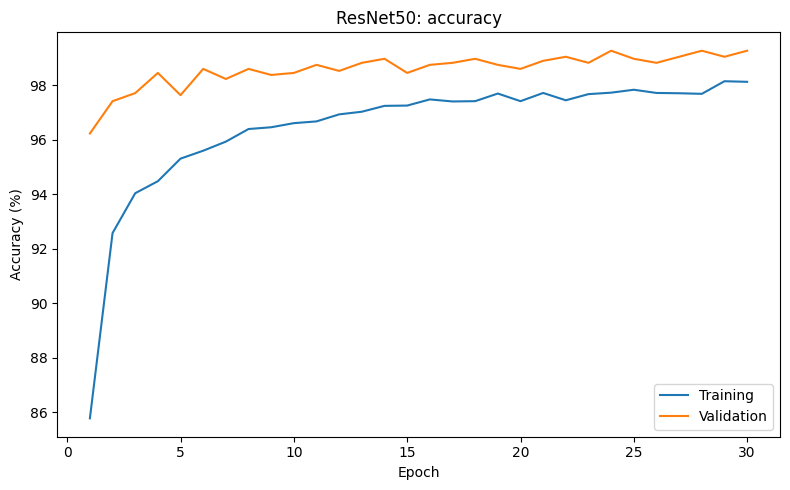

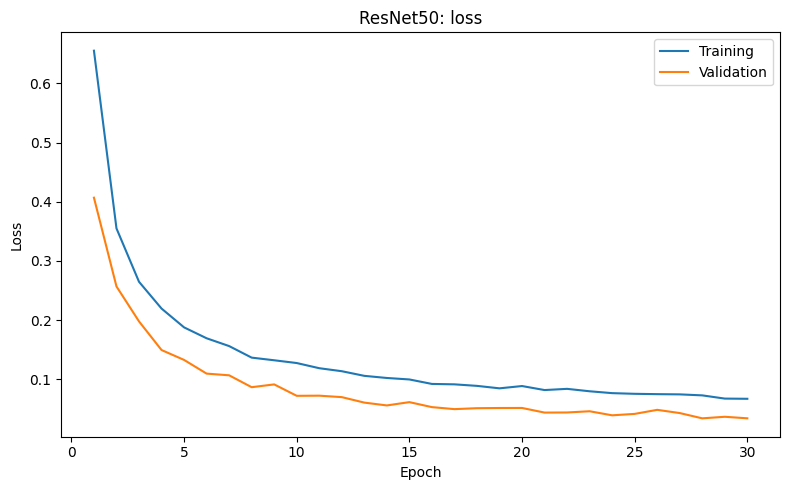

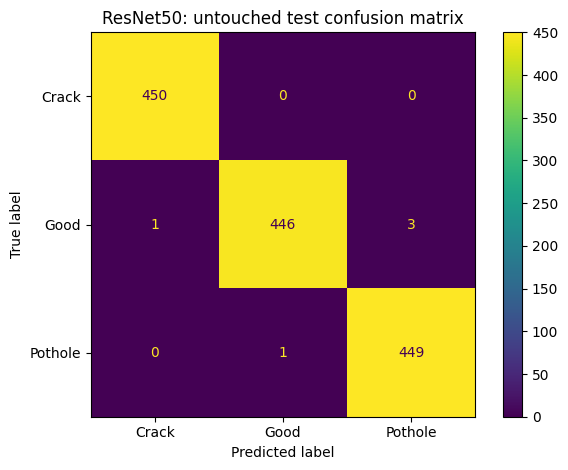


Test summary:


,Model,Best epoch,Test images,Test loss,Accuracy (%),Weighted precision,Weighted recall,Weighted F1,Macro precision,Macro recall,Macro F1,Weighted AUC,Macro AUC,Random seed
0,ResNet50,28,1350,0.027121,99.62963,0.996303,0.996296,0.996294,0.996303,0.996296,0.996294,0.999956,0.999956,17



Per-class metrics:


,precision,recall,f1-score,support
Crack,0.997783,1.000000,0.998890,450.000000
Good,0.997763,0.991111,0.994426,450.000000
Pothole,0.993363,0.997778,0.995565,450.000000
accuracy,0.996296,0.996296,0.996296,0.996296
macro avg,0.996303,0.996296,0.996294,1350.000000
weighted avg,0.996303,0.996296,0.996294,1350.000000



MODEL: DenseNet121


DenseNet121 epoch 1/30:   0%|          | 0/582 [00:00<?, ?it/s]

... (55 outputs left out)

DenseNet121 epoch 29/30:   0%|          | 0/582 [00:00<?, ?it/s]

DenseNet121 | Epoch 29 | Train loss=0.10610, Train acc=96.45% | Val loss=0.03591, Val acc=99.04% | LR=5.00e-05


DenseNet121 epoch 30/30:   0%|          | 0/582 [00:00<?, ?it/s]

DenseNet121 | Epoch 30 | Train loss=0.10351, Train acc=96.65% | Val loss=0.04238, Val acc=98.81% | LR=2.50e-05
Reloaded best DenseNet121 checkpoint from epoch 26 (validation loss=0.033895).


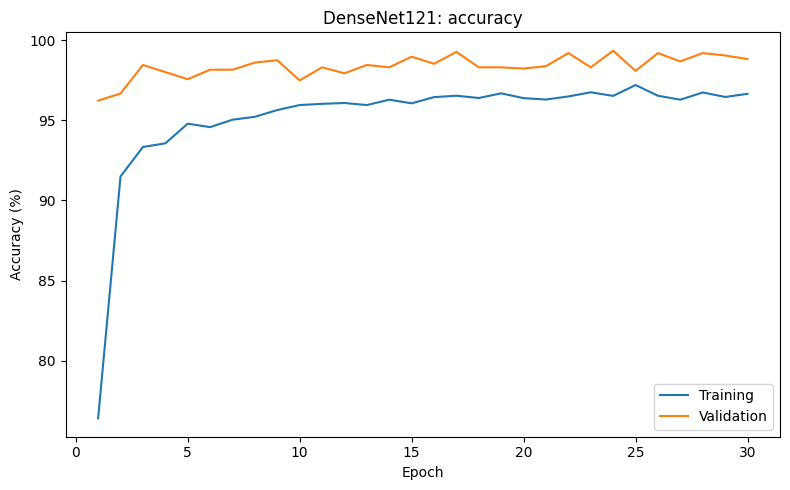

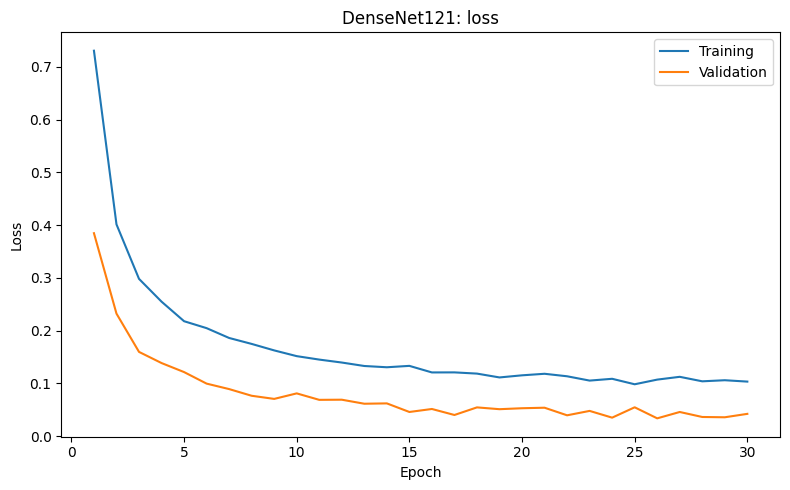

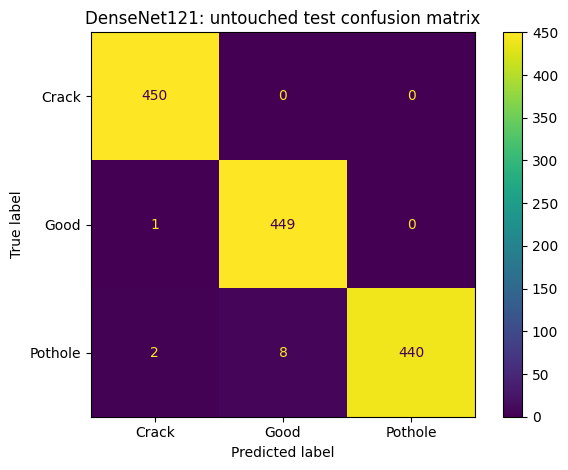


Test summary:


,Model,Best epoch,Test images,Test loss,Accuracy (%),Weighted precision,Weighted recall,Weighted F1,Macro precision,Macro recall,Macro F1,Weighted AUC,Macro AUC,Random seed
0,DenseNet121,26,1350,0.032305,99.185185,0.991957,0.991852,0.99184,0.991957,0.991852,0.99184,0.999965,0.999965,17



Per-class metrics:


,precision,recall,f1-score,support
Crack,0.993377,1.000000,0.996678,450.000000
Good,0.982495,0.997778,0.990077,450.000000
Pothole,1.000000,0.977778,0.988764,450.000000
accuracy,0.991852,0.991852,0.991852,0.991852
macro avg,0.991957,0.991852,0.991840,1350.000000
weighted avg,0.991957,0.991852,0.991840,1350.000000



MODEL: MobileNetV2


MobileNetV2 epoch 1/30:   0%|          | 0/582 [00:00<?, ?it/s]

... (55 outputs left out)

MobileNetV2 epoch 29/30:   0%|          | 0/582 [00:00<?, ?it/s]

MobileNetV2 | Epoch 29 | Train loss=0.14007, Train acc=95.44% | Val loss=0.09934, Val acc=96.44% | LR=2.50e-05


MobileNetV2 epoch 30/30:   0%|          | 0/582 [00:00<?, ?it/s]

MobileNetV2 | Epoch 30 | Train loss=0.14441, Train acc=95.33% | Val loss=0.10415, Val acc=96.96% | LR=1.25e-05
Reloaded best MobileNetV2 checkpoint from epoch 22 (validation loss=0.079010).


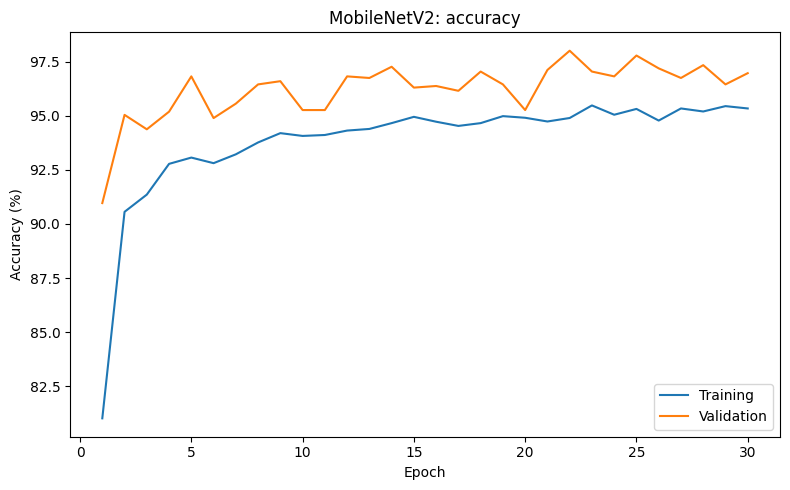

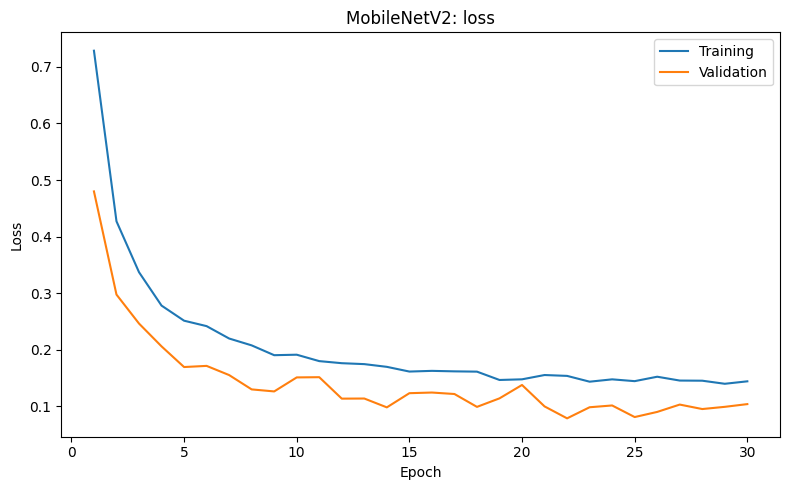

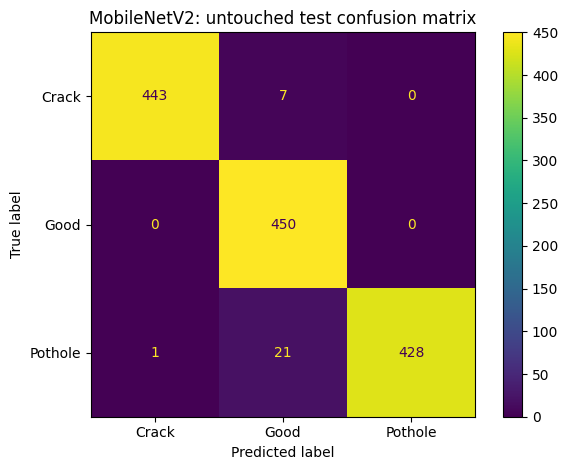


Test summary:


,Model,Best epoch,Test images,Test loss,Accuracy (%),Weighted precision,Weighted recall,Weighted F1,Macro precision,Macro recall,Macro F1,Weighted AUC,Macro AUC,Random seed
0,MobileNetV2,22,1350,0.075575,97.851852,0.979723,0.978519,0.978607,0.979723,0.978519,0.978607,0.99966,0.99966,17



Per-class metrics:


,precision,recall,f1-score,support
Crack,0.997748,0.984444,0.991051,450.000000
Good,0.941423,1.000000,0.969828,450.000000
Pothole,1.000000,0.951111,0.974943,450.000000
accuracy,0.978519,0.978519,0.978519,0.978519
macro avg,0.979723,0.978519,0.978607,1350.000000
weighted avg,0.979723,0.978519,0.978607,1350.000000



MODEL: EfficientNetB0


EfficientNetB0 epoch 1/30:   0%|          | 0/582 [00:00<?, ?it/s]

... (55 outputs left out)

EfficientNetB0 epoch 29/30:   0%|          | 0/582 [00:00<?, ?it/s]

EfficientNetB0 | Epoch 29 | Train loss=0.13865, Train acc=95.10% | Val loss=0.10439, Val acc=95.85% | LR=5.00e-05


EfficientNetB0 epoch 30/30:   0%|          | 0/582 [00:00<?, ?it/s]

EfficientNetB0 | Epoch 30 | Train loss=0.13852, Train acc=95.09% | Val loss=0.04844, Val acc=98.81% | LR=5.00e-05
Reloaded best EfficientNetB0 checkpoint from epoch 30 (validation loss=0.048437).


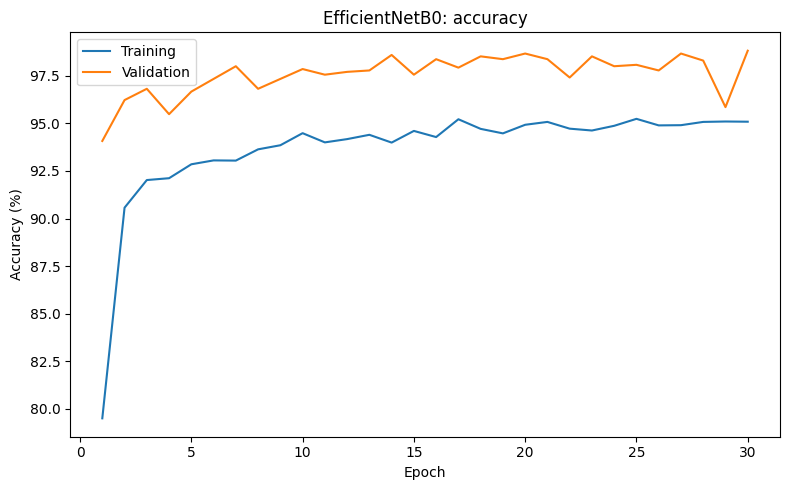

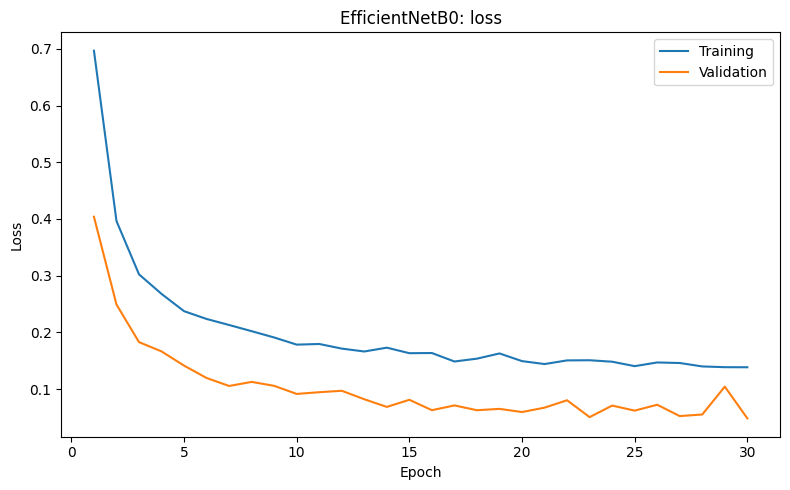

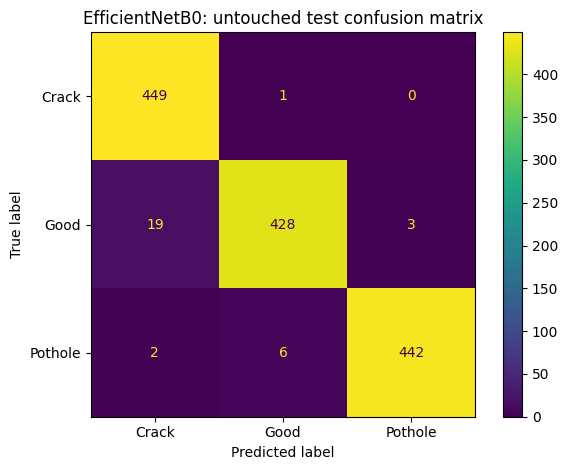


Test summary:


,Model,Best epoch,Test images,Test loss,Accuracy (%),Weighted precision,Weighted recall,Weighted F1,Macro precision,Macro recall,Macro F1,Weighted AUC,Macro AUC,Random seed
0,EfficientNetB0,30,1350,0.064725,97.703704,0.977495,0.977037,0.977009,0.977495,0.977037,0.977009,0.99929,0.99929,17



Per-class metrics:


,precision,recall,f1-score,support
Crack,0.955319,0.997778,0.976087,450.000000
Good,0.983908,0.951111,0.967232,450.000000
Pothole,0.993258,0.982222,0.987709,450.000000
accuracy,0.977037,0.977037,0.977037,0.977037
macro avg,0.977495,0.977037,0.977009,1350.000000
weighted avg,0.977495,0.977037,0.977009,1350.000000



FINAL PERFORMANCE SUMMARY


,Model,Best epoch,Test images,Test loss,Accuracy (%),Weighted precision,Weighted recall,Weighted F1,Macro precision,Macro recall,Macro F1,Weighted AUC,Macro AUC,Random seed
0,ResNet50,28,1350,0.027121,99.629630,0.996303,0.996296,0.996294,0.996303,0.996296,0.996294,0.999956,0.999956,17
1,DenseNet121,26,1350,0.032305,99.185185,0.991957,0.991852,0.991840,0.991957,0.991852,0.991840,0.999965,0.999965,17
2,MobileNetV2,22,1350,0.075575,97.851852,0.979723,0.978519,0.978607,0.979723,0.978519,0.978607,0.999660,0.999660,17
3,EfficientNetB0,30,1350,0.064725,97.703704,0.977495,0.977037,0.977009,0.977495,0.977037,0.977009,0.999290,0.999290,17


Saved: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\results_strict095\model_performance_summary.csv


In [28]:

MODEL_NAMES = [
    "ResNet50",
    "DenseNet121",
    "MobileNetV2",
    "EfficientNetB0",
]

all_model_summaries = []
all_class_reports = {}

for model_name in MODEL_NAMES:
    print("\n" + "=" * 80)
    print("MODEL:", model_name)
    print("=" * 80)

    set_global_seed(SEED)
    model = create_model(model_name)

    model, history_df, checkpoint_path, best_epoch = train_one_model(
        model,
        model_name,
        train_loader,
        val_loader,
    )

    save_training_plots(history_df, model_name)

    summary, class_report = evaluate_and_save_test_results(
        model,
        model_name,
        test_loader,
        best_epoch,
    )

    all_model_summaries.append(summary)
    all_class_reports[model_name] = class_report

    print("\nTest summary:")
    display(pd.DataFrame([summary]))

    print("\nPer-class metrics:")
    display(class_report)

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

performance_df = pd.DataFrame(all_model_summaries)
performance_path = RESULTS_ROOT / "model_performance_summary.csv"
performance_df.to_csv(performance_path, index=False)

print("\nFINAL PERFORMANCE SUMMARY")
display(performance_df)
print("Saved:", performance_path)


## 14. Produce a compact verification summary

This machine-readable summary records the final split, augmentation, leakage-control, seed, and model-selection settings.


In [29]:

reviewer_summary = {
    "raw_dataset_directory": str(RAW_ROOT),
    "processed_dataset_directory": str(PROCESSED_ROOT),
    "similarity_feature_extractor": "ImageNet-pretrained ResNet50 penultimate features",
    "similarity_metric": "cosine similarity",
    "similarity_threshold": SIMILARITY_THRESHOLD,
    "scene_grouping": "within-class complete-linkage clustering",
    "split_method": "scene-group-level balanced assignment",
    "target_split_ratio": SPLIT_RATIOS,
    "random_seed": SEED,
    "scene_overlap_across_splits": 0,
    "exact_sha256_duplicates_across_splits": exact_cross_split_duplicates,
    "validation_augmented_images": int(
        augmented_counts.loc["val"].sum()
    ),
    "test_augmented_images": int(
        augmented_counts.loc["test"].sum()
    ),
    "training_augmented_images": int(
        augmented_counts.loc["train"].sum()
    ),
    "best_checkpoint_selection": "minimum validation loss",
    "test_usage": "final evaluation after reloading the best validation checkpoint",
}

reviewer_summary_path = PROJECT_ROOT / "reviewer_verification_summary.json"
with open(reviewer_summary_path, "w", encoding="utf-8") as file:
    json.dump(reviewer_summary, file, indent=2)

print(json.dumps(reviewer_summary, indent=2))
print("Saved:", reviewer_summary_path)


{
  "raw_dataset_directory": "F:\\Road Dataset\\Raw Data",
  "processed_dataset_directory": "F:\\Road Dataset\\Corrected_Revision_Run\\OriginalMethod_Strict095\\processed_scene_split_12000_strict095",
  "similarity_feature_extractor": "ImageNet-pretrained ResNet50 penultimate features",
  "similarity_metric": "cosine similarity",
  "similarity_threshold": 0.95,
  "scene_grouping": "within-class complete-linkage clustering",
  "split_method": "scene-group-level balanced assignment",
  "target_split_ratio": {
    "train": 0.7,
    "val": 0.15,
    "test": 0.15
  },
  "random_seed": 17,
  "scene_overlap_across_splits": 0,
  "exact_sha256_duplicates_across_splits": 0,
  "validation_augmented_images": 0,
  "test_augmented_images": 0,
  "training_augmented_images": 3000,
  "best_checkpoint_selection": "minimum validation loss",
  "test_usage": "final evaluation after reloading the best validation checkpoint"
}
Saved: F:\Road Dataset\Corrected_Revision_Run\OriginalMethod_Strict095\reviewer_ve

# Principal outputs

The workflow writes the following principal outputs under `PROJECT_ROOT`:

- `scene_split.csv`
- `split_summary.csv`
- `dataset_manifest.csv`
- `reviewer_verification_summary.json`
- `processed_scene_split_12000_strict095/`
- `results_strict095/model_performance_summary.csv`
- `results_strict095/classification_report_*.csv`
- `results_strict095/confusion_matrix_*.csv`
- `results_strict095/confusion_matrix_*.png`
- `results_strict095/history_*.csv`
- `results_strict095/best_*.pth`

The completed run used similarity threshold **0.95**, seed **17**, a class-balanced 70:15:15 original-image split, training-only augmentation, and an untouched validation/test protocol.


# Reproducibility note

The finalized workflow uses a cosine-similarity threshold of **0.95**, fixed seed **17**, Windows DataLoader workers set to **0**, training-only augmentation, minimum-validation-loss checkpoint selection, and final evaluation on the untouched test subset.
